In [1]:
%pip -q install scikit-learn pandas tqdm pillow matplotlib

In [20]:
import os
import gc
import re
import shutil
import random
import zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score
from google.colab import drive, files

drive.mount('/content/drive')

SEED = 42
IMAGE_SIZE = 384
BATCH_SIZE = 48
EPOCHS = 100
PATIENCE = 5
NUM_WORKERS = 4
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
CLASS_NAMES = ['no_dr', 'mild', 'moderate', 'severe', 'proliferative_dr']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
SPLIT_DIR = Path('/content/drive/MyDrive/DR_Project/splits')
OUTPUT_DIR = Path('/content/drive/MyDrive/DR_Project/HybridViT_RGB_Vessel_TwoInput_Stage2_Comparison')
WORK_DIR = Path('/content/stage2_mobilenet_experiment')
EXTRACT_DIR = WORK_DIR / 'stage2_input'
LOCAL_IMAGE_ROOT = Path('/content/dr_images')
DRIVE_IMAGE_ROOTS = [
    Path('/content/drive/MyDrive/Dataset_extracted/colored_images/colored_images'),
    Path('/content/drive/MyDrive/Dataset/colored_images/colored_images')
]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.backends.cudnn.benchmark = USE_AMP
print('Device:', DEVICE)
print('Input size:', IMAGE_SIZE)
print('Saved outputs:', OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Input size: 384
Saved outputs: /content/drive/MyDrive/DR_Project/HybridViT_RGB_Vessel_TwoInput_Stage2_Comparison


In [3]:
print('Upload the ZIP containing Stage 2 predicted vessel masks.')
uploaded = files.upload()
zip_candidates = [Path(name) for name in uploaded if str(name).lower().endswith('.zip')]
if len(zip_candidates) != 1:
    raise ValueError('Upload exactly one ZIP file containing the Stage 2 mask folder.')
zip_path = zip_candidates[0]
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
allowed_parts = {'stage2_masks', 'stage2', 'stage_2'}

with zipfile.ZipFile(zip_path, 'r') as archive:
    entries = [info for info in archive.infolist() if not info.is_dir() and any(part.lower() in allowed_parts for part in Path(info.filename.replace('\\', '/')).parts)]
    if not entries:
        raise RuntimeError('The ZIP does not contain a stage2_masks, stage2, or stage_2 folder.')
    for item in tqdm(entries, desc='Extracting Stage 2 files'):
        name = item.filename.replace('\\', '/')
        target = (EXTRACT_DIR / name).resolve()
        if not target.is_relative_to(EXTRACT_DIR.resolve()):
            raise ValueError('ZIP contains an unsafe path.')
        target.parent.mkdir(parents=True, exist_ok=True)
        if not target.exists() or target.stat().st_size != item.file_size:
            with archive.open(item) as source, open(target, 'wb') as destination:
                shutil.copyfileobj(source, destination)

mask_roots = [p for p in EXTRACT_DIR.rglob('*') if p.is_dir() and p.name.lower() in allowed_parts]
if not mask_roots:
    raise RuntimeError('Stage 2 folder was not found after extraction.')

def count_masks(directory):
    return sum(p.is_file() and p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'} for p in directory.rglob('*'))

MASK_ROOT = max(mask_roots, key=count_masks)
if count_masks(MASK_ROOT) == 0:
    raise RuntimeError('No vessel-mask image files in the Stage 2 folder.')
print('Using Stage 2 mask folder:', MASK_ROOT)
print('Stage 2 mask files:', count_masks(MASK_ROOT))

Upload the ZIP containing Stage 2 predicted vessel masks.


Saving stage2_masks.zip to stage2_masks.zip


Extracting Stage 2 files:   0%|          | 0/35127 [00:00<?, ?it/s]

Using Stage 2 mask folder: /content/stage2_mobilenet_experiment/stage2_input/stage2_masks
Stage 2 mask files: 35126


In [4]:
folder_to_label = {
    'no_dr': 0,
    'nodr': 0,
    'mild': 1,
    'moderate': 2,
    'severe': 3,
    'proliferate_dr': 4,
    'proliferative_dr': 4,
    'proliferative': 4,
    'pdr': 4
}

mask_files = sorted(p for p in MASK_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'})
mask_by_id = {}
for p in mask_files:
    key = re.sub(r'(?i)(_s2|_stage2)$', '', p.stem)
    if key in mask_by_id:
        raise RuntimeError(f'Duplicate Stage 2 vessel mask for image {key}')
    mask_by_id[key] = p

csv_candidates = sorted(MASK_ROOT.rglob('*.csv'), key=lambda p: (p.name.lower() != 'stage2_mask_paths.csv', len(p.parts)))
labels_by_id = {}
for csv_path in csv_candidates:
    try:
        sample = pd.read_csv(csv_path)
        if {'img_path', 'label'}.issubset(sample.columns):
            for rec in sample[['img_path', 'label']].itertuples(index=False):
                if pd.isna(rec.img_path) or pd.isna(rec.label):
                    continue
                key = Path(str(rec.img_path)).stem
                value = int(rec.label)
                if key in labels_by_id and labels_by_id[key] != value:
                    raise RuntimeError(f'Conflicting CSV labels for {key}')
                labels_by_id[key] = value
            print('Loaded original labels from:', csv_path)
            break
    except (UnicodeDecodeError, pd.errors.ParserError):
        continue

records = []
for key, p in mask_by_id.items():
    folder_label = next((folder_to_label[parent.name.lower()] for parent in p.parents if parent != MASK_ROOT and MASK_ROOT in parent.parents and parent.name.lower() in folder_to_label), None)
    label = labels_by_id.get(key, folder_label)
    if label is None:
        raise RuntimeError(f'No DR severity label for Stage 2 mask {p}. The folder or CSV must provide labels.')
    if folder_label is not None and label != folder_label:
        raise RuntimeError(f'CSV severity does not match Stage 2 folder for {key}')
    if label not in range(5):
        raise RuntimeError(f'Unexpected severity label {label} for {key}')
    records.append({'image_id': key, 'label': label, 'mask_path': str(p)})

metadata = pd.DataFrame(records)
if metadata.empty:
    raise RuntimeError('No Stage 2 mask records found.')
print('Stage 2 records:', len(metadata))
print(metadata['label'].value_counts().sort_index().reindex(range(5), fill_value=0).rename(index=dict(enumerate(CLASS_NAMES))))

Loaded original labels from: /content/stage2_mobilenet_experiment/stage2_input/stage2_masks/stage2_mask_paths.csv
Stage 2 records: 35126
label
no_dr               25810
mild                 2443
moderate             5292
severe                873
proliferative_dr      708
Name: count, dtype: int64


In [5]:
DRIVE_IMAGE_ROOT = next((p for p in DRIVE_IMAGE_ROOTS if p.is_dir()), None)
if DRIVE_IMAGE_ROOT is None:
    raise FileNotFoundError('Original RGB image folder was not found in either known Google Drive location.')

rgb_sources = [p for p in DRIVE_IMAGE_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}]
if not rgb_sources:
    raise RuntimeError('No DR RGB images found in Google Drive.')

def copy_with_retry(src):
    destination = LOCAL_IMAGE_ROOT / src.relative_to(DRIVE_IMAGE_ROOT)
    destination.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(4):
        try:
            if destination.exists() and destination.stat().st_size == src.stat().st_size:
                return None
            shutil.copyfile(src, destination)
            if destination.stat().st_size != src.stat().st_size:
                raise IOError('File size mismatch')
            return None
        except Exception as exc:
            if attempt == 3:
                return str(src), str(exc)
    return None

errors = []
with ThreadPoolExecutor(max_workers=8) as pool:
    tasks = [pool.submit(copy_with_retry, source) for source in rgb_sources]
    for task in tqdm(as_completed(tasks), total=len(tasks), desc='Copying RGB images from Google Drive'):
        failure = task.result()
        if failure:
            errors.append(failure)
if errors:
    raise RuntimeError(f'RGB copying failed for {len(errors)} files. First failure: {errors[0]}')

rgb_by_id = {}
for path in LOCAL_IMAGE_ROOT.rglob('*'):
    if not path.is_file() or path.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
        continue
    if path.stem in rgb_by_id:
        raise RuntimeError(f'Duplicate RGB image ID: {path.stem}')
    rgb_by_id[path.stem] = path

missing = set(metadata['image_id']) - set(rgb_by_id)
if missing:
    raise RuntimeError(f'{len(missing)} Stage 2 masks do not have corresponding RGB images. Example: {sorted(missing)[:5]}')
metadata['img_path'] = metadata['image_id'].map(lambda key: str(rgb_by_id[key]))
metadata['basename'] = metadata['img_path'].map(lambda value: Path(value).name)
print('RGB source:', DRIVE_IMAGE_ROOT)
print('RGB images available:', len(rgb_by_id))
print('Masks matched to RGB:', len(metadata))

Copying RGB images from Google Drive:   0%|          | 0/35126 [00:00<?, ?it/s]

RGB source: /content/drive/MyDrive/Dataset_extracted/colored_images/colored_images
RGB images available: 35126
Masks matched to RGB: 35126


In [16]:
def read_split(name):
    path = SPLIT_DIR / f'stage1_{name}_names.txt'
    if not path.exists():
        raise FileNotFoundError(path)
    names = [Path(line.strip()).stem for line in path.read_text().splitlines() if line.strip()]
    if len(names) != len(set(names)):
        raise RuntimeError(f'Duplicate image IDs in {path.name}')
    return set(names)

train_ids = read_split('train')
val_ids = read_split('val')
test_ids = read_split('test')

if train_ids & val_ids or train_ids & test_ids or val_ids & test_ids:
    raise RuntimeError('Train, validation and test splits overlap.')

available = set(metadata['image_id'])
missing_ids = (train_ids | val_ids | test_ids) - available
if missing_ids:
    raise RuntimeError(f'{len(missing_ids)} split images do not have Stage 2 masks and RGB images. Examples: {sorted(missing_ids)[:6]}')

unassigned = available - (train_ids | val_ids | test_ids)
if unassigned:
    raise RuntimeError(f'{len(unassigned)} Stage 2 images are not assigned by saved Stage 1 splits.')

train_df = metadata[metadata['image_id'].isin(train_ids)].reset_index(drop=True)
val_df = metadata[metadata['image_id'].isin(val_ids)].reset_index(drop=True)
test_df = metadata[metadata['image_id'].isin(test_ids)].reset_index(drop=True)
counts = np.bincount(train_df['label'].to_numpy(dtype=np.int64), minlength=5)
if (counts == 0).any():
    raise RuntimeError('At least one DR class is missing from training.')
print('Train:', len(train_df), 'Validation:', len(val_df), 'Test:', len(test_df))
print(pd.DataFrame({'class': CLASS_NAMES, 'train_count': counts}))
print('Split overlap:', len(train_ids & val_ids), len(train_ids & test_ids), len(val_ids & test_ids))
metadata[['image_id', 'label', 'img_path', 'mask_path']].to_csv(OUTPUT_DIR / 'stage2_matched_data.csv', index=False)

Train: 24588 Validation: 5269 Test: 5269
              class  train_count
0             no_dr        18067
1              mild         1710
2          moderate         3704
3            severe          611
4  proliferative_dr          496
Split overlap: 0 0 0


In [26]:
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.transforms import functional as TF
from torch.utils.data import WeightedRandomSampler
from sklearn.metrics import roc_auc_score
import json

IMAGE_SIZE = 384
BATCH_SIZE = 16
EPOCHS = 100
PATIENCE = 5
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.05
FOCAL_GAMMA = 2.0 # Gamma controls how much focal loss focuses on difficult examples
AUX_WEIGHT = 0.4 # The auxiliary CNN loss is multiplied by this value during training
MASK_GATE_STRENGTH = 0.5 # Controls how strongly the vessel mask changes the image features
USE_TEST_TTA = True
OUTPUT_DIR = Path('/content/drive/MyDrive/DR_Project/HybridViT_RGB_Vessel_TwoInput_Stage2_Comparison')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class DRHybridDataset(Dataset):
    def __init__(self, frame, use_masks, train=False):
        self.rows = frame[['img_path', 'mask_path', 'label']].to_dict('records')
        self.use_masks = use_masks
        self.train = train
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(row['img_path']) as image_file:
            image = image_file.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
        if self.use_masks:
            with Image.open(row['mask_path']) as mask_file:
                vessel = mask_file.convert('L').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.NEAREST)
            vessel = vessel.point(lambda value: 255 if value >= 127 else 0)# Make the mask binary: vessel pixels are white and other pixels are black
        else:
            vessel = Image.new('L', (IMAGE_SIZE, IMAGE_SIZE), 0)  # Use an all-black mask for the zero-mask experiment
        if self.train:
            if random.random() < 0.5:      # Apply the  flip and rotation to the image and mask
                image = TF.hflip(image)
                vessel = TF.hflip(vessel)
            if random.random() < 0.5:
                image = TF.vflip(image)
                vessel = TF.vflip(vessel)
            angle = random.uniform(-15, 15)
            image = TF.rotate(image, angle, interpolation=TF.InterpolationMode.BILINEAR)
            vessel = TF.rotate(vessel, angle, interpolation=TF.InterpolationMode.NEAREST)
            image = ImageEnhance.Color(image).enhance(random.uniform(0.9, 1.1))
            image = ImageEnhance.Brightness(image).enhance(random.uniform(0.9, 1.1))
        image = TF.normalize(TF.to_tensor(image), [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        vessel = (TF.to_tensor(vessel) >= 0.5).float() # Convert the mask to a one-channel tensor containing 0s and 1s
        return image, vessel, torch.tensor(int(row['label']), dtype=torch.long)

class HybridViT(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        pretrained = resnet50(weights=ResNet50_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(pretrained.children())[:-2])
        self.feature_adapter = nn.Conv2d(2048, 512, 1)
        self.vessel_gate = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.GELU(), # Adds a smooth activation so the model can learn more complex mask patterns
            nn.Conv2d(32, 512, kernel_size=1, bias=False)
        )
        self.class_token = nn.Parameter(torch.zeros(1, 1, 512))
        self.position_embedding = nn.Parameter(torch.zeros(1, 50, 512)) # Store a position value for the class token and each image token
        layer = nn.TransformerEncoderLayer(d_model=512, nhead=8, dim_feedforward=2048, dropout=0.2, activation='gelu', batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=6, enable_nested_tensor=False)
        self.auxiliary_classifier = nn.Linear(512, num_classes)
        # This classifier combines the CNN features and the Transformer class token
        self.classifier = nn.Sequential(nn.LayerNorm(1024), nn.Linear(1024, 512), nn.GELU(), nn.Dropout(0.2), nn.Linear(512, num_classes))
        nn.init.normal_(self.class_token, std=0.02)
        nn.init.normal_(self.position_embedding, std=0.02)
        nn.init.kaiming_normal_(self.feature_adapter.weight, mode='fan_out', nonlinearity='relu')
        if self.feature_adapter.bias is not None:
            nn.init.zeros_(self.feature_adapter.bias)
    def forward(self, image, vessel_mask):
        features = self.feature_adapter(self.backbone(image)) # Extract image features and reduce them to channels
        if vessel_mask.ndim != 4 or vessel_mask.shape[1] != 1:
            raise ValueError('Expected vessel masks with shape [batch, 1, height, width]')
        vessel_low = F.adaptive_avg_pool2d(vessel_mask.float(), features.shape[-2:])
        adjustment = torch.tanh(self.vessel_gate(vessel_low))
        features = features * (1.0 + MASK_GATE_STRENGTH * adjustment)
        features = F.adaptive_avg_pool2d(features, (7, 7))
        pooled = features.mean(dim=(2, 3)) # Average the feature map to create the CNN feature vector
        auxiliary_logits = self.auxiliary_classifier(pooled)
        tokens = features.flatten(2).transpose(1, 2)
        cls = self.class_token.expand(image.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.position_embedding
        tokens = self.transformer(tokens) #Transformer process the image tokens
        logits = self.classifier(torch.cat([tokens[:, 0], pooled], dim=1))
        return logits, auxiliary_logits

def focal_loss(logits, targets):
    log_probs = F.log_softmax(logits.float(), dim=1) # Get the predicted probability assigned to each class
    log_pt = log_probs.gather(1, targets.view(-1, 1)).squeeze(1)
    pt = log_pt.exp()
    return (-(1.0 - pt).pow(FOCAL_GAMMA) * log_pt).mean()

def make_loaders(use_masks):
    train_data = DRHybridDataset(train_df, use_masks, True)
    val_data = DRHybridDataset(val_df, use_masks, False)
    test_data = DRHybridDataset(test_df, use_masks, False)
    class_counts = np.bincount(train_df['label'].to_numpy(dtype=np.int64), minlength=5)
    frequencies = 1.0 / class_counts[train_df['label'].to_numpy(dtype=np.int64)]
    sampler = WeightedRandomSampler(torch.as_tensor(frequencies, dtype=torch.double), num_samples=len(train_data), replacement=True)
    kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=USE_AMP)
    return (DataLoader(train_data, sampler=sampler, **kw), DataLoader(val_data, shuffle=False, **kw), DataLoader(test_data, shuffle=False, **kw))


In [34]:
import time
from tqdm.auto import tqdm

def calculate_metrics(y_true, y_pred, probabilities):
    result = {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'weighted_f1': float(f1_score(y_true, y_pred, average='weighted', zero_division=0)),
        'macro_precision': float(precision_score(y_true, y_pred, average='macro', zero_division=0)),
        'macro_recall': float(recall_score(y_true, y_pred, average='macro', zero_division=0)),
    }
    try:
        result['macro_auroc'] = float(roc_auc_score(y_true, probabilities, multi_class='ovr', average='macro', labels=list(range(5))))
    except ValueError:
        result['macro_auroc'] = None
    return result

@torch.no_grad()
def evaluate_hybrid(model, loader, test_augmentation=False):
    model.eval()
    all_labels, all_predictions, all_probabilities = [], [], []
    total_loss = 0.0
    total_samples = 0
    for rgb, vessel_mask, labels in loader:
        rgb = rgb.to(DEVICE, non_blocking=True)
        vessel_mask = vessel_mask.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', enabled=USE_AMP):
            logits, aux_logits = model(rgb, vessel_mask)
            loss = focal_loss(logits, labels) + AUX_WEIGHT * focal_loss(aux_logits, labels)
            if test_augmentation:
                h_logits, _ = model(torch.flip(rgb, dims=[3]), torch.flip(vessel_mask, dims=[3]))
                v_logits, _ = model(torch.flip(rgb, dims=[2]), torch.flip(vessel_mask, dims=[2]))
                logits = (logits + h_logits + v_logits) / 3.0
        probabilities = F.softmax(logits.float(), dim=1)
        total_loss += float(loss.item()) * labels.numel()
        total_samples += labels.numel()
        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(probabilities.argmax(1).cpu().tolist())
        all_probabilities.append(probabilities.cpu().numpy())
    all_probabilities = np.concatenate(all_probabilities, axis=0)
    metrics = calculate_metrics(all_labels, all_predictions, all_probabilities)
    metrics['loss'] = total_loss / max(1, total_samples)
    return metrics, np.array(all_labels), np.array(all_predictions), all_probabilities

def run_hybrid_experiment(name, with_stage2_masks):
    seed_everything(SEED)
    checkpoint = OUTPUT_DIR / f'{name}_best.pt'
    weights_path = OUTPUT_DIR / f'{name}_best_weights.pth'
    latest_checkpoint = OUTPUT_DIR / f'{name}_latest_epoch.pt'
    history_path = OUTPUT_DIR / f'{name}_history.csv'
    model = HybridViT(5).to(DEVICE)
    best_epoch = None
    history = []
    needs_training = not weights_path.is_file() and not checkpoint.is_file()

    if not needs_training:
        if weights_path.is_file():
            saved_weights = torch.load(weights_path, map_location=DEVICE, weights_only=True)
            model.load_state_dict(saved_weights)
            print('Loaded existing trained weights:', weights_path)
        else:
            saved = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
            model.load_state_dict(saved['model'])
            torch.save(model.state_dict(), weights_path)
            print('Loaded existing best checkpoint:', checkpoint)
            print('Saved weights-only copy:', weights_path)
            print('The checkpoint might be from an interrupted training run.')
        if checkpoint.is_file():
            metadata = torch.load(checkpoint, map_location='cpu', weights_only=True)
            best_epoch = metadata.get('best_epoch')
        if history_path.is_file():
            history = pd.read_csv(history_path).to_dict('records')
            print(f'Previously recorded epoch history: {history_path}')
            for row in history:
                epoch_number = int(row['epoch'])
                selected = ' | SELECTED BEST WEIGHTS' if best_epoch is not None and epoch_number == int(best_epoch) else ''
                print(
                    f'{name} | Epoch {epoch_number}/{EPOCHS} | '
                    f'train_loss={float(row["train_focal_loss"]):.4f} | '
                    f'val_loss={float(row["val_focal_loss"]):.4f} | '
                    f'val_accuracy={float(row["val_accuracy"]):.4f} | '
                    f'val_macro_f1={float(row["val_macro_f1"]):.4f}'
                    f'{selected}'
                )
            print('These are saved HISTORY records, not separate weight checkpoints for each epoch.')
        else:
            print('No previous epoch-history CSV found; only saved model weights can be reported.')
        print(f'Existing best weights loaded | Best epoch: {best_epoch}')
        print('No new epochs trained or saved because trained weights already exist.')
        test_loader = DataLoader(
            DRHybridDataset(test_df, with_stage2_masks, False),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=USE_AMP
        )
        print('Training skipped. Evaluating saved model:', name)
    else:
        print('No saved model found. Starting training:', name)
        train_loader, val_loader, test_loader = make_loaders(with_stage2_masks)
        optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
        scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
        best_macro_f1 = -1.0
        best_epoch = 0
        stale_epochs = 0
        for epoch in range(1, EPOCHS + 1):
            model.train()
            train_loss_sum = 0.0
            train_seen = 0
            start = time.time()
            progress_bar = tqdm(
                train_loader,
                desc=f'{name} | Epoch {epoch}/{EPOCHS}',
                total=len(train_loader),
                leave=False,
                dynamic_ncols=True
            )
            for rgb, vessel_mask, labels in progress_bar:
                rgb = rgb.to(DEVICE, non_blocking=True)
                vessel_mask = vessel_mask.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type='cuda', enabled=USE_AMP):
                    logits, aux_logits = model(rgb, vessel_mask)
                    loss = focal_loss(logits, labels) + AUX_WEIGHT * focal_loss(aux_logits, labels)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                train_loss_sum += float(loss.item()) * labels.numel()
                train_seen += labels.numel()
                progress_bar.set_postfix(
                    train_loss=f'{train_loss_sum / max(train_seen, 1):.4f}',
                    lr=f'{optimizer.param_groups[0]["lr"]:.2e}'
                )
            progress_bar.close()
            val_metrics, _, _, _ = evaluate_hybrid(model, val_loader)
            epoch_row = {
                'epoch': epoch,
                'train_focal_loss': train_loss_sum / max(train_seen, 1),
                'val_focal_loss': val_metrics['loss'],
                'val_accuracy': val_metrics['accuracy'],
                'val_macro_f1': val_metrics['macro_f1'],
                'lr': optimizer.param_groups[0]['lr'],
                'seconds': time.time() - start
            }
            history.append(epoch_row)
            print(name, epoch_row)
            if val_metrics['macro_f1'] > best_macro_f1 + 1e-8:
                best_macro_f1 = val_metrics['macro_f1']
                best_epoch = epoch
                stale_epochs = 0
                torch.save({'model': model.state_dict(), 'best_epoch': epoch, 'val_macro_f1': best_macro_f1}, checkpoint)
                print(f'Epoch {epoch}/{EPOCHS}: NEW BEST weights saved | Macro-F1: {best_macro_f1:.4f} | {checkpoint}')
            else:
                stale_epochs += 1
                print(f'Epoch {epoch}/{EPOCHS}: Best weights unchanged | Best epoch: {best_epoch}')
            scheduler.step()
            torch.save({
                'model': model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'scheduler': scheduler.state_dict(),
                'scaler': scaler.state_dict(),
                'epoch': epoch,
                'best_epoch': best_epoch,
                'best_macro_f1': best_macro_f1,
                'stale_epochs': stale_epochs
            }, latest_checkpoint)
            pd.DataFrame(history).to_csv(history_path, index=False)
            print(f'Epoch {epoch}/{EPOCHS}: Latest training checkpoint SAVED | {latest_checkpoint}')
            if stale_epochs >= PATIENCE:
                break
        saved = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
        model.load_state_dict(saved['model'])
        torch.save(model.state_dict(), weights_path)
        pd.DataFrame(history).to_csv(history_path, index=False)
        print('Saved best model checkpoint:', checkpoint)
        print('Saved best model weights:', weights_path)

    results, y_true, y_pred, probabilities = evaluate_hybrid(model, test_loader, test_augmentation=USE_TEST_TTA)
    results.update({'experiment': name, 'best_epoch': best_epoch, 'test_samples': len(y_true)})
    print('Test result:', results)
    pd.DataFrame(
        classification_report(y_true, y_pred, labels=list(range(5)), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    ).transpose().to_csv(OUTPUT_DIR / f'{name}_per_class_report.csv')
    pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=list(range(5))), index=CLASS_NAMES, columns=CLASS_NAMES
    ).to_csv(OUTPUT_DIR / f'{name}_confusion_matrix.csv')
    with open(OUTPUT_DIR / f'{name}_metrics.json', 'w') as f:
        json.dump(results, f, indent=2)
    del model, test_loader
    if needs_training:
        del optimizer, scaler, train_loader, val_loader
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return results, pd.DataFrame(history, columns=['epoch', 'train_focal_loss', 'val_focal_loss', 'val_accuracy', 'val_macro_f1', 'lr', 'seconds']), y_true, y_pred

print('Experiment A: RGB + real Stage 2 predicted vessel masks')
metrics_a, history_a, labels_a, predictions_a = run_hybrid_experiment('rgb_with_stage2_masks', True)
print('Experiment B: RGB + zero vessel masks')
metrics_b, history_b, labels_b, predictions_b = run_hybrid_experiment('rgb_with_zero_masks', False)


Experiment A: RGB + real Stage 2 predicted vessel masks
Loaded existing trained weights: /content/drive/MyDrive/DR_Project/HybridViT_RGB_Vessel_TwoInput_Stage2_Comparison/rgb_with_stage2_masks_best_weights.pth
Previously recorded epoch history: /content/drive/MyDrive/DR_Project/HybridViT_RGB_Vessel_TwoInput_Stage2_Comparison/rgb_with_stage2_masks_history.csv
rgb_with_stage2_masks | Epoch 1/100 | train_loss=0.8891 | val_loss=0.9503 | val_accuracy=0.3257 | val_macro_f1=0.3539
rgb_with_stage2_masks | Epoch 2/100 | train_loss=0.7030 | val_loss=0.8228 | val_accuracy=0.4067 | val_macro_f1=0.3109
rgb_with_stage2_masks | Epoch 3/100 | train_loss=0.5909 | val_loss=0.6379 | val_accuracy=0.5874 | val_macro_f1=0.4254
rgb_with_stage2_masks | Epoch 4/100 | train_loss=0.5264 | val_loss=0.5326 | val_accuracy=0.7231 | val_macro_f1=0.4850 | SELECTED BEST WEIGHTS
rgb_with_stage2_masks | Epoch 5/100 | train_loss=0.4889 | val_loss=0.6276 | val_accuracy=0.6115 | val_macro_f1=0.4408
rgb_with_stage2_masks | E

In [36]:
import pandas as pd
from pathlib import Path
from IPython.display import display

OUTPUT_DIR = Path(
    '/content/drive/MyDrive/DR_Project/HybridViT_RGB_Vessel_TwoInput_Stage2_Comparison'
)

for name, title in [
    ('rgb_with_stage2_masks', 'Experiment A: RGB + Stage 2 Vessel Masks'),
    ('rgb_with_zero_masks', 'Experiment B: RGB + Zero Masks')
]:
    report_path = OUTPUT_DIR / f'{name}_per_class_report.csv'

    print(f'\n{"=" * 75}')
    print(title)
    print(f'{"=" * 75}')

    if report_path.exists():
        report = pd.read_csv(report_path, index_col=0)
        display(report.round(4))
    else:
        print('Classification results not available yet.')


Experiment A: RGB + Stage 2 Vessel Masks


,precision,recall,f1-score,support
no_dr,0.8563,0.8683,0.8623,3872.0000
mild,0.1211,0.1585,0.1373,366.0000
moderate,0.5453,0.3942,0.4576,794.0000
severe,0.3952,0.6336,0.4868,131.0000
proliferative_dr,0.7000,0.5283,0.6022,106.0000
accuracy,0.7349,0.7349,0.7349,0.7349
macro avg,0.5236,0.5166,0.5092,5269.0000
weighted avg,0.7438,0.7349,0.7364,5269.0000



Experiment B: RGB + Zero Masks


,precision,recall,f1-score,support
no_dr,0.8530,0.8665,0.8597,3872.000
mild,0.1214,0.1393,0.1298,366.000
moderate,0.5238,0.4018,0.4547,794.000
severe,0.3689,0.6336,0.4663,131.000
proliferative_dr,0.6585,0.5094,0.5745,106.000
accuracy,0.7330,0.7330,0.7330,0.733
macro avg,0.5051,0.5101,0.4970,5269.000
weighted avg,0.7367,0.7330,0.7325,5269.000


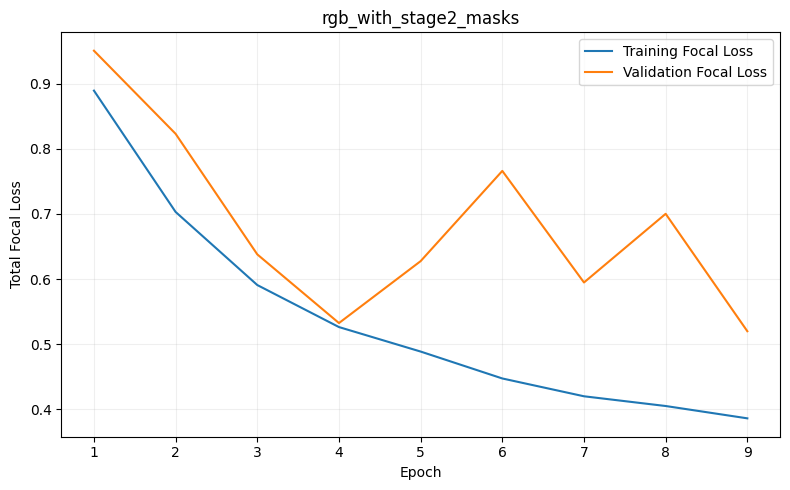

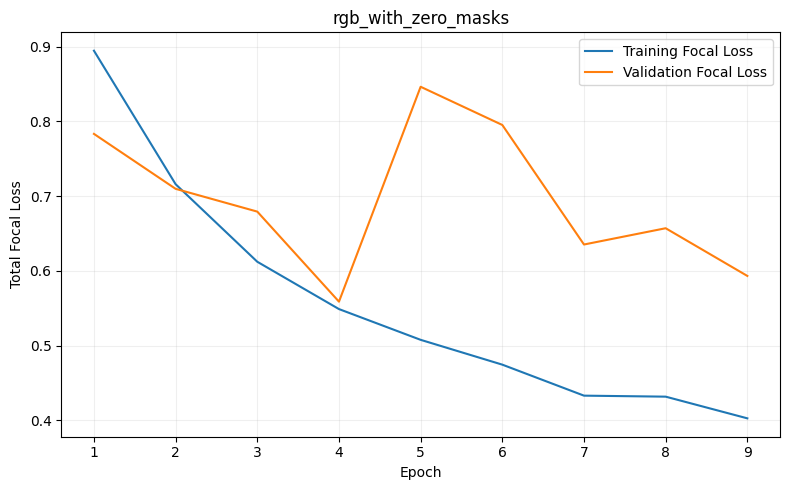

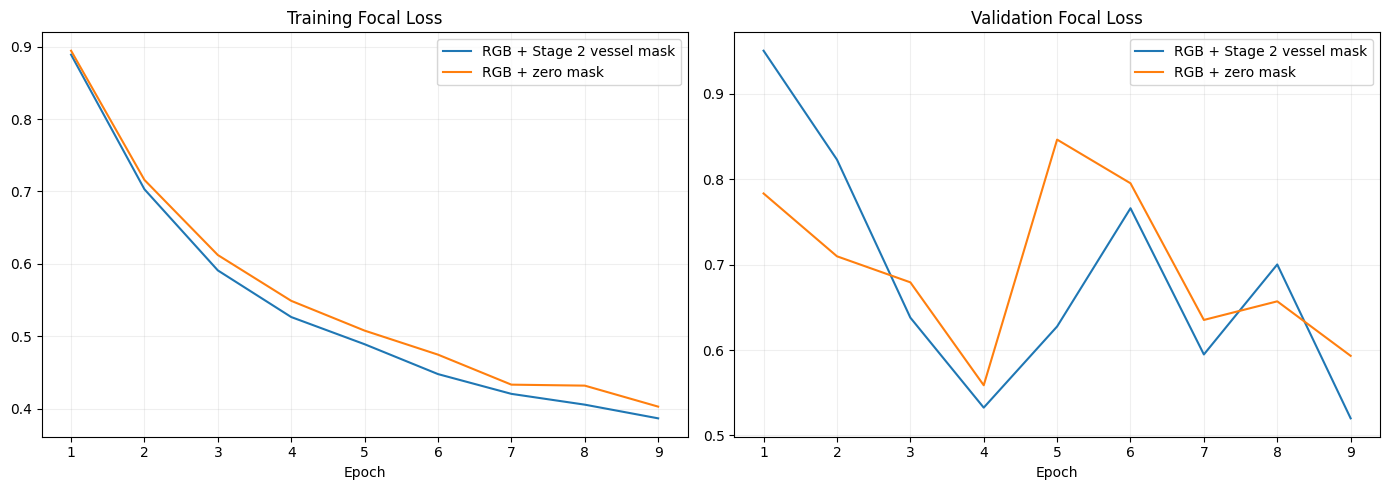

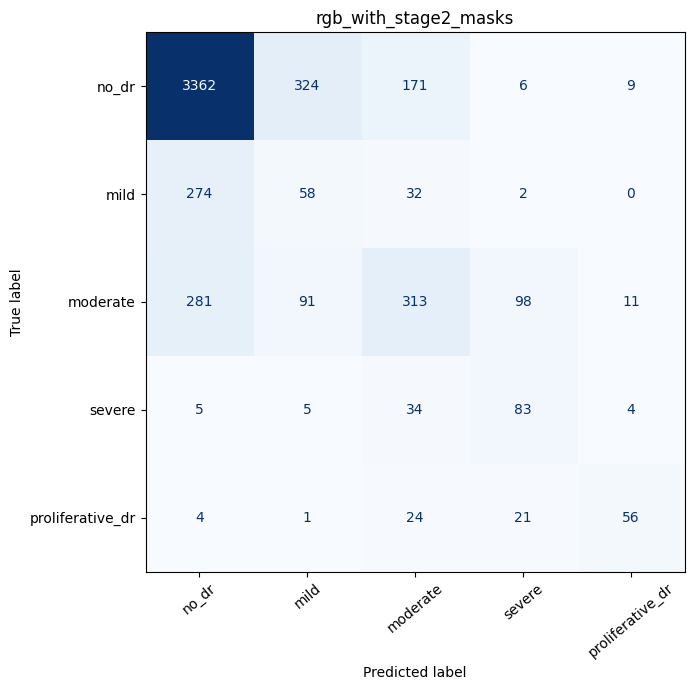

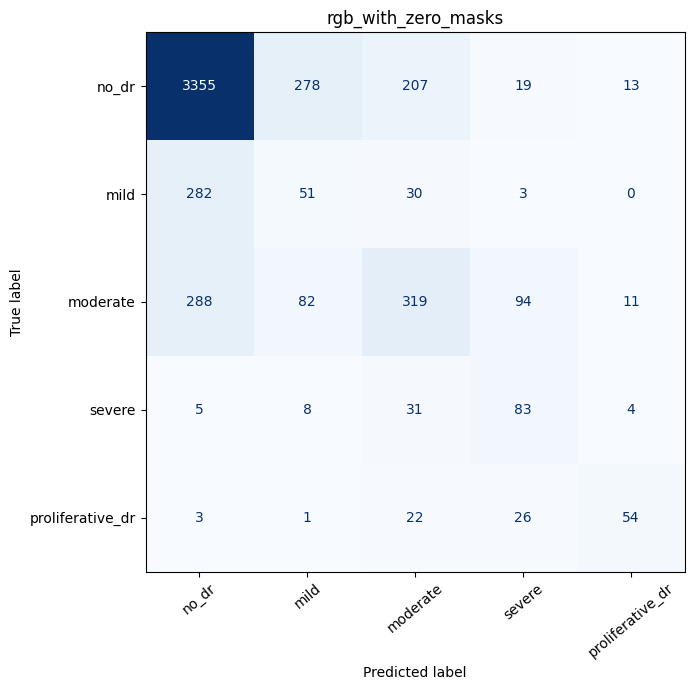

experiment       rgb_with_stage2_masks  rgb_with_zero_masks
accuracy                      0.734864             0.732966
macro_f1                      0.509221             0.496995
weighted_f1                   0.736363             0.732457
macro_precision               0.523592             0.505140
macro_recall                  0.516570             0.510121
macro_auroc                   0.830432             0.825952
loss                          0.529701             0.549628
best_epoch                    4.000000             4.000000
test_samples               5269.000000          5269.000000


In [37]:
def plot_hybrid_loss(history, name):
    plt.figure(figsize=(8, 5))
    plt.plot(history['epoch'], history['train_focal_loss'], label='Training Focal Loss')
    plt.plot(history['epoch'], history['val_focal_loss'], label='Validation Focal Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Total Focal Loss')
    plt.title(name)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{name}_loss.png', dpi=180)
    plt.show()

plot_hybrid_loss(history_a, 'rgb_with_stage2_masks')
plot_hybrid_loss(history_b, 'rgb_with_zero_masks')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for hist, label in [(history_a, 'RGB + Stage 2 vessel mask'), (history_b, 'RGB + zero mask')]:
    axes[0].plot(hist['epoch'], hist['train_focal_loss'], label=label)
    axes[1].plot(hist['epoch'], hist['val_focal_loss'], label=label)
for axis, title in zip(axes, ['Training Focal Loss', 'Validation Focal Loss']):
    axis.set_title(title)
    axis.set_xlabel('Epoch')
    axis.legend()
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'hybridvit_loss_comparison.png', dpi=180)
plt.show()

from sklearn.metrics import ConfusionMatrixDisplay
for name, y_true, y_pred in [('rgb_with_stage2_masks', labels_a, predictions_a), ('rgb_with_zero_masks', labels_b, predictions_b)]:
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(5)), display_labels=CLASS_NAMES, xticks_rotation=40, ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{name}_confusion_matrix.png', dpi=180)
    plt.show()

summary = pd.DataFrame([metrics_a, metrics_b]).set_index('experiment')
summary.to_csv(OUTPUT_DIR / 'hybridvit_test_comparison.csv')
print(summary.transpose().to_string())
